In [1]:
!pip install numpy opencv-python matplotlib scipy scikit-image pandas

In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import scipy
import skimage
import pandas as pd

print("All libraries imported successfully!")
print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)
print("Scikit-image:", skimage.__version__)

All libraries imported successfully!
NumPy: 2.4.6
OpenCV: 5.0.0
Scikit-image: 0.25.2


In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

project_path = "/content/drive/MyDrive/Image_Processing_Project"

print(os.listdir(project_path))

['Concrete400']


In [5]:
for root, dirs, files in os.walk(project_path):
    print(f"\nFolder: {root}")
    print("Subfolders:", dirs[:5])
    print("Files:", files[:5])


Folder: /content/drive/MyDrive/Image_Processing_Project
Subfolders: ['Concrete400']
Files: []

Folder: /content/drive/MyDrive/Image_Processing_Project/Concrete400
Subfolders: ['Object Detection', 'Segmentation', 'Classification']
Files: ['README.md']

Folder: /content/drive/MyDrive/Image_Processing_Project/Concrete400/Object Detection
Subfolders: ['Boxes', 'Boxes_visualizations']
Files: []

Folder: /content/drive/MyDrive/Image_Processing_Project/Concrete400/Object Detection/Boxes
Subfolders: []
Files: ['image_001.txt', 'image_002.txt', 'image_003.txt', 'image_004.txt', 'image_005.txt']

Folder: /content/drive/MyDrive/Image_Processing_Project/Concrete400/Object Detection/Boxes_visualizations
Subfolders: []
Files: ['image_001_bbox.png', 'image_002_bbox.png', 'image_003_bbox.png', 'image_004_bbox.png', 'image_005_bbox.png']

Folder: /content/drive/MyDrive/Image_Processing_Project/Concrete400/Segmentation
Subfolders: ['Masks', 'Image']
Files: []

Folder: /content/drive/MyDrive/Image_Proce

In [6]:
import os
from pathlib import Path

dataset_path = Path(
    "/content/drive/MyDrive/Image_Processing_Project/Concrete400/Segmentation"
)

images_path = dataset_path / "Image"
masks_path = dataset_path / "Masks"

print("Images folder exists:", images_path.exists())
print("Masks folder exists:", masks_path.exists())

Images folder exists: True
Masks folder exists: True


In [7]:
# Get all image files
image_files = {
    file.stem for file in images_path.iterdir()
    if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

# Get all mask files
mask_files = {
    file.stem for file in masks_path.iterdir()
    if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

# Compare filenames
matched_files = image_files & mask_files
images_without_masks = image_files - mask_files
masks_without_images = mask_files - image_files

print("Total Images:", len(image_files))
print("Total Masks:", len(mask_files))
print("Matched Pairs:", len(matched_files))
print("Images without Masks:", len(images_without_masks))
print("Masks without Images:", len(masks_without_images))

print("\nFirst 10 matched files:")
print(sorted(matched_files)[:10])

print("\nImages without Masks:")
print(sorted(images_without_masks)[:10])

print("\nMasks without Images:")
print(sorted(masks_without_images)[:10])

Total Images: 379
Total Masks: 379
Matched Pairs: 379
Images without Masks: 0
Masks without Images: 0

First 10 matched files:
['image_001', 'image_002', 'image_003', 'image_004', 'image_005', 'image_006', 'image_007', 'image_008', 'image_009', 'image_010']

Images without Masks:
[]

Masks without Images:
[]


Image shape: (512, 512, 3)
Mask shape: (512, 512)
Image dtype: uint8
Mask dtype: uint8
Mask minimum: 0
Mask maximum: 255
Unique mask values: [ 0  1  2  3  4  5  6  7  8  9 10 12 13 14 15 17 18 19 20 21]


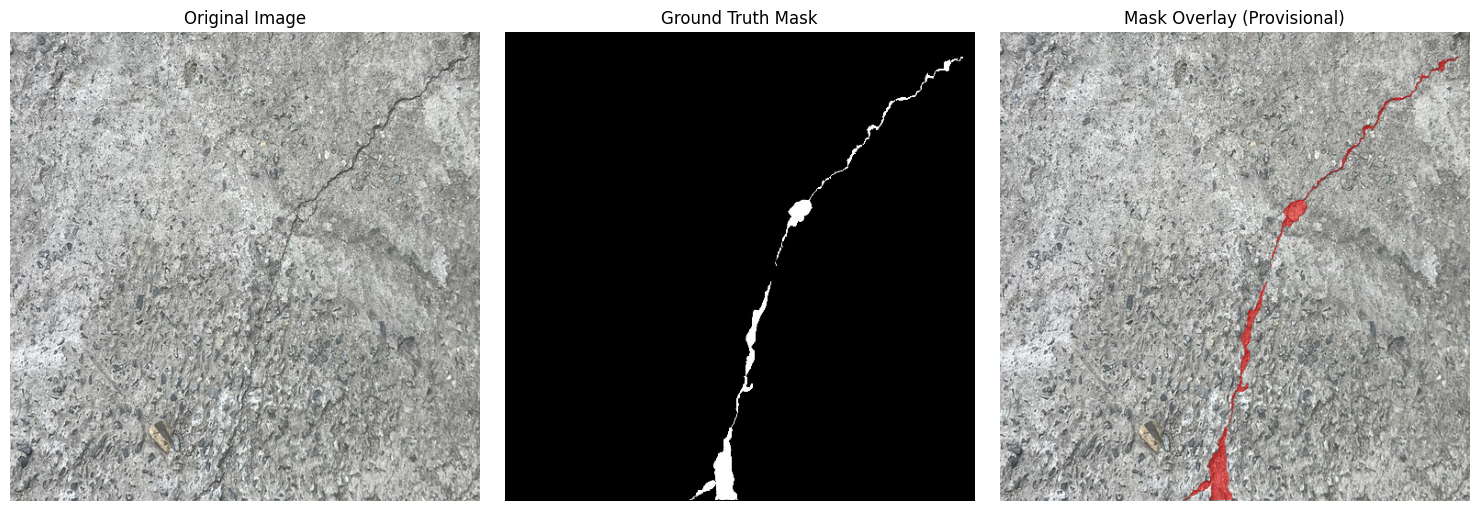

In [8]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Select one sample
sample_name = "image_001.jpg"

# Read original image and ground truth mask
image = cv2.imread(str(images_path / sample_name))
mask = cv2.imread(str(masks_path / sample_name), cv2.IMREAD_GRAYSCALE)

# Convert original image from BGR to RGB
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Print image information
print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Image dtype:", image.dtype)
print("Mask dtype:", mask.dtype)
print("Mask minimum:", mask.min())
print("Mask maximum:", mask.max())
print("Unique mask values:", np.unique(mask)[:20])

# Create a provisional binary mask for visualization
binary_mask = mask > 127

# Create overlay
overlay = image.copy()
overlay[binary_mask] = (
    0.5 * overlay[binary_mask] + 0.5 * np.array([255, 0, 0])
).astype(np.uint8)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Mask Overlay (Provisional)")
plt.axis("off")

plt.tight_layout()
plt.show()